# Statistical Modelling with Machine Learning

## Proje Amacı
İlk Önce Projeyi bu adresten aldım : https://thecleverprogrammer.com/2024/04/25/statistical-modelling-using-python/


İstatistiksel modellemenin kullanımını açıklamak için, müzik özelliklerinin istatistiksel modellemesi görevini ele alacağım. Burada, müzik parçalarının popülerliğini hangi müzik özelliklerinin belirlediğini belirlemeyi hedefleyeceğiz. 

### importing

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
df =pd.read_csv('musicdata.csv')

In [6]:
df.head()

,Unnamed: 0,Track Name,Artists,Album Name,Album ID,Track ID,Popularity,Release Date,Duration (ms),Explicit,...,Energy,Key,Loudness,Mode,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo
0,0,Bijlee Bijlee,Harrdy Sandhu,Bijlee Bijlee,3tG0IGB24sRhGFLs5F1Km8,1iZLpuGMr4tn1F5bZu32Kb,70,2021-10-30,168450,False,...,0.670,1,-5.313,0,0.1430,0.2690,0.000000,0.0733,0.643,100.004
1,1,Expert Jatt,Nawab,Expert Jatt,2gibg5SCTep0wsIMefGzkd,7rr6n1NFIcQXCsi43P0YNl,65,2018-01-18,199535,False,...,0.948,6,-2.816,0,0.1990,0.2980,0.000000,0.0784,0.647,172.038
2,2,"Kaun Nachdi (From ""Sonu Ke Titu Ki Sweety"")","Guru Randhawa, Neeti Mohan",High Rated Gabru - Guru Randhawa,6EDbwGsQNQRLf73c7QwZ2f,3s7m0jmCXGcM8tmlvjCvAa,64,2019-03-02,183373,False,...,0.830,4,-3.981,0,0.0455,0.0357,0.000000,0.0419,0.753,127.999
3,3,Na Na Na Na,J Star,Na Na Na Na,4xBqgoiRSOMU1VlKuntVQW,5GjxbFTZAMhrVfVrNrrwrG,52,2015,209730,False,...,0.863,3,-3.760,1,0.0413,0.3760,0.000014,0.0916,0.807,95.000
4,4,Patiala Peg,Diljit Dosanjh,Do Gabru - Diljit Dosanjh & Akhil,1uxDllRe9CPhdr8rhz2QCZ,6TikcWOLRsPq66GBx2jk67,46,2018-07-10,188314,False,...,0.811,5,-3.253,0,0.1840,0.0259,0.000000,0.3110,0.835,175.910


## EDA - Exploratory Data Analysis

In [8]:
df.shape

(100, 22)

In [9]:
df.sample()

,Unnamed: 0,Track Name,Artists,Album Name,Album ID,Track ID,Popularity,Release Date,Duration (ms),Explicit,...,Energy,Key,Loudness,Mode,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo
75,75,"Psycho Saiyaan (From ""Saaho"")","Sachet Tandon, Dhvani Bhanushali, Tanishk Bagchi","Psycho Saiyaan (From ""Saaho"")",1sywArD1z0FvcfsN1MK9GE,3ZjMdVOWxQ53FKrmkgCv95,67,2019-07-08,166461,False,...,0.722,10,-2.604,0,0.158,0.0363,0.000004,0.452,0.848,189.857


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        100 non-null    int64  
 1   Track Name        94 non-null     object 
 2   Artists           94 non-null     object 
 3   Album Name        94 non-null     object 
 4   Album ID          100 non-null    object 
 5   Track ID          100 non-null    object 
 6   Popularity        100 non-null    int64  
 7   Release Date      100 non-null    object 
 8   Duration (ms)     100 non-null    int64  
 9   Explicit          100 non-null    bool   
 10  External URLs     100 non-null    object 
 11  Danceability      100 non-null    float64
 12  Energy            100 non-null    float64
 13  Key               100 non-null    int64  
 14  Loudness          100 non-null    float64
 15  Mode              100 non-null    int64  
 16  Speechiness       100 non-null    float64
 17

In [11]:
df.describe()

,Unnamed: 0,Popularity,Duration (ms),Danceability,Energy,Key,Loudness,Mode,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo
count,100.000000,100.000000,100.000000,100.000000,100.00000,100.00000,100.000000,100.00000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,49.500000,50.950000,210543.180000,0.767210,0.79763,4.54000,-4.399930,0.43000,0.115615,0.165559,0.005236,0.185791,0.659259,119.371470
std,29.011492,16.496326,37961.050214,0.085302,0.11572,3.64434,1.612703,0.49757,0.075819,0.152536,0.028979,0.170086,0.183901,29.058698
min,0.000000,0.000000,141862.000000,0.501000,0.47700,0.00000,-8.272000,0.00000,0.029400,0.001090,0.000000,0.034600,0.073900,78.991000
25%,24.750000,46.000000,186098.500000,0.714750,0.71125,1.00000,-5.465250,0.00000,0.057700,0.037500,0.000000,0.076900,0.558250,97.042500
50%,49.500000,56.500000,205076.000000,0.772000,0.81700,4.00000,-4.252500,0.00000,0.086150,0.128000,0.000000,0.122000,0.672500,107.984000
75%,74.250000,62.000000,226079.000000,0.826500,0.88125,7.25000,-3.163250,1.00000,0.160000,0.236750,0.000041,0.225250,0.793750,132.259000
max,99.000000,72.000000,367818.000000,0.959000,0.98800,11.00000,-0.223000,1.00000,0.340000,0.620000,0.270000,0.823000,0.940000,189.857000


In [12]:
df.corr(numeric_only=True)  # corelasyon hesaplıyor

,Unnamed: 0,Popularity,Duration (ms),Explicit,Danceability,Energy,Key,Loudness,Mode,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo
Unnamed: 0,1.000000,-0.281101,0.225136,-0.067894,0.053296,0.046162,0.230055,-0.183362,0.273251,-0.093104,-0.235924,0.109805,0.038011,-0.005886,0.041336
Popularity,-0.281101,1.000000,-0.122820,0.012553,0.085615,-0.163800,-0.067426,0.056394,-0.222557,-0.089060,0.170999,-0.331343,-0.024051,0.064333,-0.183226
Duration (ms),0.225136,-0.122820,1.000000,-0.101601,0.014128,0.272514,0.074083,-0.141667,0.157455,0.093384,-0.028696,-0.001204,0.065974,-0.035099,0.161854
Explicit,-0.067894,0.012553,-0.101601,1.000000,0.144216,0.071027,0.040467,-0.004702,-0.087293,0.237653,0.004265,-0.018250,0.360014,0.050939,-0.081185
Danceability,0.053296,0.085615,0.014128,0.144216,1.000000,-0.091658,0.091846,-0.113396,0.121365,0.001322,0.008154,0.047264,0.056034,0.140812,-0.163149
Energy,0.046162,-0.163800,0.272514,0.071027,-0.091658,1.000000,0.035041,0.539004,-0.010366,0.021439,-0.009198,-0.075488,0.191540,0.196330,-0.027892
Key,0.230055,-0.067426,0.074083,0.040467,0.091846,0.035041,1.000000,-0.030018,-0.235185,-0.025298,-0.064841,-0.004923,0.041893,-0.043331,0.037409
Loudness,-0.183362,0.056394,-0.141667,-0.004702,-0.113396,0.539004,-0.030018,1.000000,-0.113481,0.104368,0.014259,-0.284634,-0.019779,0.192207,0.004624
Mode,0.273251,-0.222557,0.157455,-0.087293,0.121365,-0.010366,-0.235185,-0.113481,1.000000,-0.120420,-0.137478,-0.005770,-0.105034,0.121413,0.008821
Speechiness,-0.093104,-0.089060,0.093384,0.237653,0.001322,0.021439,-0.025298,0.104368,-0.120420,1.000000,0.114543,0.044789,0.122421,-0.009103,0.194100


In [13]:
import seaborn as sns

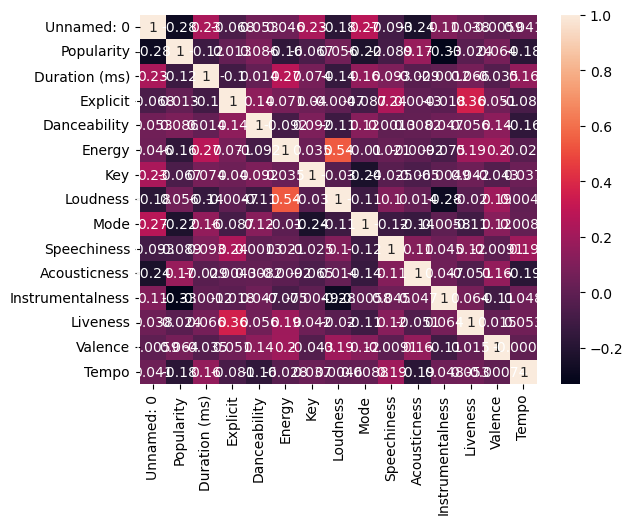

In [14]:
sns.heatmap(df.corr(numeric_only=True) ,annot=True);

ısı haritası, çeşitli özelliklerin birbirleriyle ve parçaların popülerliğiyle nasıl ilişkili olduğuna dair içgörüler sağlar. Özellikle, Popülerlik, Gürültü ve Enerji ile bir miktar pozitif korelasyona sahipken, Akustiklik ile hafif negatif korelasyonlara sahiptir. Bu, daha gürültülü ve daha enerjik parçaların daha popüler olma eğiliminde olduğunu, daha akustik parçaların ise daha az popüler olma eğiliminde olduğunu göstermektedir.

Dans edilebilirlik ve Valans (bir parçanın ilettiği müzikal pozitiflik) da popülerlikle pozitif bir korelasyon gösteriyor; bu da daha dans edilebilir ve daha mutlu bir tona sahip parçaların dinleyiciler tarafından tercih edilebileceğini gösteriyor.

In [16]:
df.tail()

,Unnamed: 0,Track Name,Artists,Album Name,Album ID,Track ID,Popularity,Release Date,Duration (ms),Explicit,...,Energy,Key,Loudness,Mode,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo
95,95,NaN,NaN,NaN,2jw92hf4mnISbYywvU3Anj,3OZr3vo7SmYpn5XqeQEAOM,0,0000,203207,False,...,0.842,6,-4.109,1,0.0745,0.00814,0.000013,0.2120,0.915,156.051
96,96,Move Your Lakk,"Diljit Dosanjh, Badshah, Sonakshi Sinha",Move Your Lakk,0V06TMGQQQkvKxNmFlKyEj,3aYMKdSitJeHUCZO8Wt6fw,51,2017-03-29,194568,False,...,0.816,2,-5.595,1,0.1480,0.03790,0.000153,0.1230,0.744,99.992
97,97,"Patola (From ""Blackmail"")","Guru Randhawa, Preet Hundal","Patola (From ""Blackmail"")",2XAAIDEpPb57NsKgAHLGVQ,17LZzRCY0iFWlDDuAG7BlM,57,2018-03-05,184410,False,...,0.901,3,-2.719,0,0.0508,0.12600,0.000000,0.0692,0.914,87.998
98,98,"Ban Ja Rani (From ""Tumhari Sulu"")",Guru Randhawa,High Rated Gabru - Guru Randhawa,6EDbwGsQNQRLf73c7QwZ2f,7cQtGVoPCK9DlspeYjdHOA,60,2019-03-02,225938,False,...,0.692,9,-4.718,0,0.0577,0.20600,0.000000,0.1240,0.487,102.015
99,99,"Hauli Hauli (From ""De De Pyaar De"")","Garry Sandhu, Neha Kakkar, Mellow D",Dance Syndrome,6e1XB070vlPaxGDAsi8AF6,4XyKoSEWrkQjI4AekJYWNx,39,2019-09-03,209393,False,...,0.982,1,-3.376,1,0.0788,0.02120,0.000032,0.3370,0.571,94.990


In [17]:
df.isnull().sum() # hangi sütunda boş veri var

Unnamed: 0          0
Track Name          6
Artists             6
Album Name          6
Album ID            0
Track ID            0
Popularity          0
Release Date        0
Duration (ms)       0
Explicit            0
External URLs       0
Danceability        0
Energy              0
Key                 0
Loudness            0
Mode                0
Speechiness         0
Acousticness        0
Instrumentalness    0
Liveness            0
Valence             0
Tempo               0
dtype: int64

In [18]:
music_data_cleaned = df.drop(columns=['Unnamed: 0'])

In [19]:
columns_with_missing_values = ['Track Name', 'Artists', 'Album Name']
music_data_cleaned[columns_with_missing_values] = music_data_cleaned[columns_with_missing_values].fillna('Unknown')

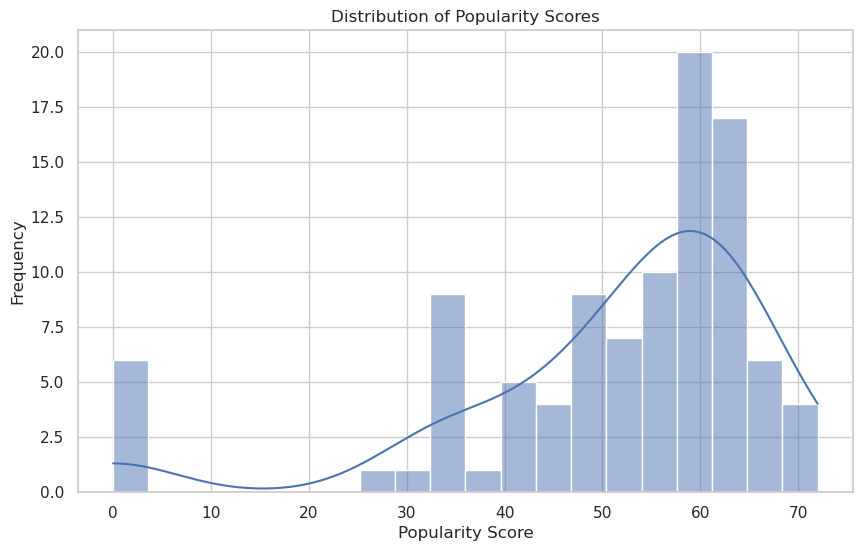

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="whitegrid")

# plotting the distribution of popularity
plt.figure(figsize=(10, 6))
sns.histplot(music_data_cleaned['Popularity'], bins=20, kde=True)
plt.title('Distribution of Popularity Scores')
plt.xlabel('Popularity Score')
plt.ylabel('Frequency')
plt.show()

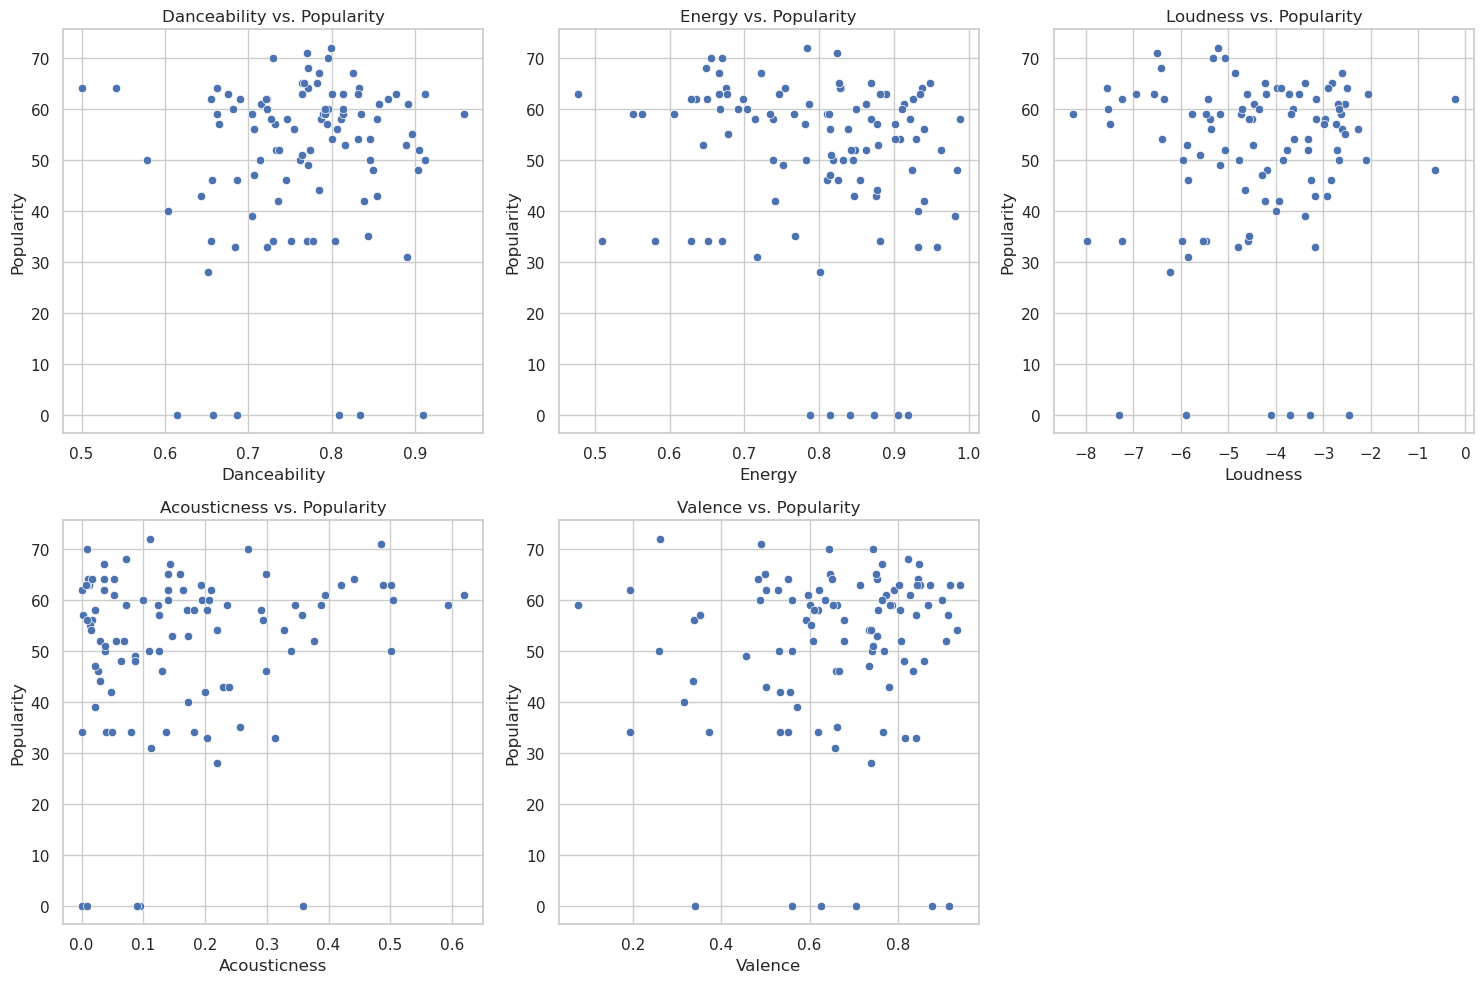

In [21]:
# creating scatter plots for various features vs. popularity
features = ['Danceability', 'Energy', 'Loudness', 'Acousticness', 'Valence']
plt.figure(figsize=(15, 10))

for i, feature in enumerate(features, 1):
    plt.subplot(2, 3, i)
    sns.scatterplot(x=music_data_cleaned[feature], y=music_data_cleaned['Popularity'])
    plt.title(f'{feature} vs. Popularity')
    plt.xlabel(feature)
    plt.ylabel('Popularity')

plt.tight_layout()
plt.show()

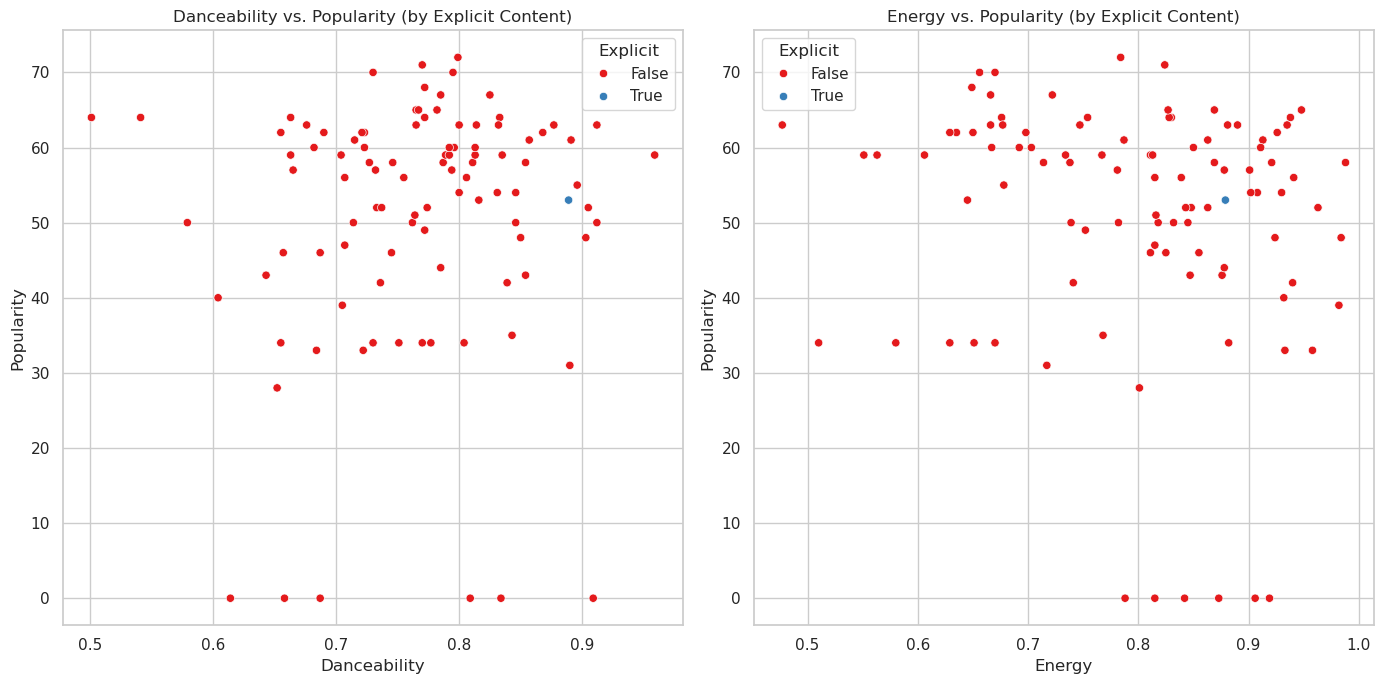

In [22]:
# creating plots for danceability vs. popularity and energy vs. popularity, segmented by explicit content
plt.figure(figsize=(14, 7))

# danceability vs. popularity
plt.subplot(1, 2, 1)
sns.scatterplot(x='Danceability', y='Popularity', hue='Explicit', data=music_data_cleaned, palette='Set1')
plt.title('Danceability vs. Popularity (by Explicit Content)')
plt.xlabel('Danceability')
plt.ylabel('Popularity')

# energy vs. popularity
plt.subplot(1, 2, 2)
sns.scatterplot(x='Energy', y='Popularity', hue='Explicit', data=music_data_cleaned, palette='Set1')
plt.title('Energy vs. Popularity (by Explicit Content)')
plt.xlabel('Energy')
plt.ylabel('Popularity')

plt.tight_layout()
plt.show()

burada popularity ve diğer yüksek olanlar arasında ki ilişkiler gösterildi.

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

# preparing the dataset for regression
# convert 'Explicit' boolean olanları sayısal yapıyor (0 or 1)
music_data_cleaned['Explicit'] = music_data_cleaned['Explicit'].astype(int)

# model için özellikleri seçiyoruz
features = ['Danceability', 'Energy', 'Loudness', 'Acousticness', 'Valence', 'Explicit', 'Key', 'Mode', 'Speechiness', 'Instrumentalness', 'Tempo']
X = music_data_cleaned[features]
y = music_data_cleaned['Popularity']

# standardizing yapıyoruz.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#  veri setlerini eğitim için ayırıyoruz.
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# initializing and training the linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# tahmin
y_pred = model.predict(X_test)

# modeli değerlendiriyoruz
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# katsayı ve performans ölçümlerini çıktı olarak alıyoruz.
coefficients = pd.Series(model.coef_, index=features)
coefficients

Danceability        1.249640e+00
Energy             -3.204815e+00
Loudness            1.141456e+00
Acousticness        2.469403e+00
Valence             2.125671e+00
Explicit           -2.131628e-14
Key                -3.189486e+00
Mode               -5.859715e+00
Speechiness         3.398224e-02
Instrumentalness    3.390750e-01
Tempo              -1.865736e+00
dtype: float64

Yukarıdaki çıktı, çeşitli müzik özelliklerinin parça popülaritesi üzerindeki etkisini ölçen regresyon modelinden elde edilen katsayıları temsil eder. Pozitif bir katsayı, özellikteki bir artışın popülerlikte bir artışla ilişkili olduğunu gösterir ve negatif bir katsayı için bunun tersi geçerlidir.

Örneğin, Dans Edilebilirlik (1.249640), Ses Yüksekliği (1.141456), Akustiklik (2.469403) ve Değerlik (2.125671) özelliklerinin hepsinin pozitif katsayıları vardır; bu da bu özelliklerde daha yüksek değerlere sahip parçaların daha popüler olma eğiliminde olduğunu göstermektedir.

In [35]:
import pickle
from sklearn.linear_model import LinearRegression

# Modelinizi oluşturun
model = LinearRegression()

# Modeli eğitin (örnek veri ile)
# model.fit(X_train, y_train)

# Modeli kaydet
with open('model.pkl', 'wb') as file:
    pickle.dump(model, file)